# PLOT2GENRE

**Objective:** Predict a movie's primary genre using only its plot summary.

This project uses:
- TMDB movie plot summaries
- Frozen `all-MiniLM-L6-v2` sentence embeddings
- A small Multi-Layer Perceptron (MLP)
- Cross-Entropy Loss
- Early Stopping
- Stratified 5-Fold Cross-Validation
- Accuracy, Precision, Recall and F1-score

### Selected Genres
Action · Adventure · Animation · Comedy · Drama · Horror

# 1. Setup and Environment

The project is implemented entirely in Google Colab.

Google Drive is used to store the project outputs and trained model.  
The required Python libraries are installed and imported, and random seeds
are fixed to improve reproducibility.

In [ ]:
import os

PROJECT_DIR = "/content/drive/MyDrive/Movie_Genre_Classifier"

os.makedirs(PROJECT_DIR, exist_ok=True)

print("Project folder:", PROJECT_DIR)

Project folder: /content/drive/MyDrive/Movie_Genre_Classifier


In [ ]:
!pip -q install sentence-transformers

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

import torch
import torch.nn as nn
from torch.utils.data import TensorDataset, DataLoader

from sklearn.model_selection import train_test_split, StratifiedKFold
from sklearn.preprocessing import LabelEncoder
from sklearn.metrics import (
    accuracy_score,
    precision_recall_fscore_support,
    classification_report,
    confusion_matrix
)

from sentence_transformers import SentenceTransformer

print("PyTorch version:", torch.__version__)
print("CUDA available:", torch.cuda.is_available())

PyTorch version: 2.11.0+cpu
CUDA available: False


In [ ]:
import random

SEED = 42

random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

print("Random seed:", SEED)

Random seed: 42


# 2. Dataset Collection

Movie metadata and plot summaries are collected directly from the TMDB API,
allowing the dataset to include movies released through 2026.

The data is retrieved programmatically inside Google Colab, so no manual
dataset download is required.

In [ ]:
from getpass import getpass

TMDB_TOKEN = getpass("Paste your TMDB API Read Access Token: ")

Paste your TMDB API Read Access Token: ··········


In [ ]:
import requests

headers = {
    "Authorization": f"Bearer {TMDB_TOKEN}",
    "accept": "application/json"
}

response = requests.get(
    "https://api.themoviedb.org/3/genre/movie/list",
    headers=headers,
    params={"language": "en"}
)

print("Status code:", response.status_code)

if response.status_code == 200:
    print(" TMDB API connected successfully!")
else:
    print(" Something went wrong:")
    print(response.text)

Status code: 200
 TMDB API connected successfully!


In [ ]:
genre_data = response.json()

genre_map = {
    genre["id"]: genre["name"]
    for genre in genre_data["genres"]
}

print(genre_map)

{28: 'Action', 12: 'Adventure', 16: 'Animation', 35: 'Comedy', 80: 'Crime', 99: 'Documentary', 18: 'Drama', 10751: 'Family', 14: 'Fantasy', 36: 'History', 27: 'Horror', 10402: 'Music', 9648: 'Mystery', 10749: 'Romance', 878: 'Science Fiction', 10770: 'TV Movie', 53: 'Thriller', 10752: 'War', 37: 'Western'}


In [ ]:
BASE_URL = "https://api.themoviedb.org/3/discover/movie"

all_movies = []

for page in range(1, 501):

    params = {
        "language": "en-US",
        "sort_by": "popularity.desc",
        "include_adult": "false",
        "include_video": "false",
        "page": page,
        "primary_release_date.gte": "1900-01-01",
        "primary_release_date.lte": "2026-09-01"
    }

    response = requests.get(
        BASE_URL,
        headers=headers,
        params=params
    )

    if response.status_code != 200:
        print("Error:", response.status_code)
        break

    data = response.json()

    all_movies.extend(data["results"])

    if page % 50 == 0:
        print(f"Collected page {page} | Movies: {len(all_movies)}")

print("\nTotal movies collected:", len(all_movies))

Collected page 50 | Movies: 1000
Collected page 100 | Movies: 2000
Collected page 150 | Movies: 3000
Collected page 200 | Movies: 4000
Collected page 250 | Movies: 5000
Collected page 300 | Movies: 6000
Collected page 350 | Movies: 7000
Collected page 400 | Movies: 8000
Collected page 450 | Movies: 9000
Collected page 500 | Movies: 10000

Total movies collected: 10000


In [ ]:
tmdb_df = pd.DataFrame(all_movies)

tmdb_df = tmdb_df[
    ["id", "title", "overview", "release_date", "genre_ids"]
].dropna()

tmdb_df["overview"] = tmdb_df["overview"].astype(str).str.strip()
tmdb_df = tmdb_df[tmdb_df["overview"].str.len() >= 30]

tmdb_df["release_date"] = pd.to_datetime(
    tmdb_df["release_date"],
    errors="coerce"
)

tmdb_df["release_year"] = tmdb_df["release_date"].dt.year

tmdb_df = tmdb_df.dropna(subset=["release_year"])
tmdb_df["release_year"] = tmdb_df["release_year"].astype(int)

tmdb_df = tmdb_df.drop_duplicates("id").reset_index(drop=True)

print("Dataset ready!")
print("Movies:", len(tmdb_df))
print("Year range:", tmdb_df["release_year"].min(), "→", tmdb_df["release_year"].max())
print("2026 movies:", (tmdb_df["release_year"] == 2026).sum())

Dataset ready!
Movies: 9768
Year range: 1901 → 2026
2026 movies: 616


# 3. Dataset Inspection and Preprocessing

The dataset is inspected for size, release-year coverage and missing values.

Each movie may contain multiple genres. For this classification task, the first
listed TMDB genre is treated as the movie's primary genre.

The six most frequent primary genres are retained, and the dataset is reduced
to approximately 7,000 movies using stratified sampling.

Dataset shape: (9768, 6)

Year range:
Earliest: 1901
Latest: 2026

2026 movies: 616


,title,release_year,overview
0,Spider-Man: Brand New Day,2026,Fighting crime full-time as Spider-Man in a wo...
1,The Odyssey,2026,"Odysseus, the legendary King of Ithaca, embark..."
2,Mutiny,2026,After witnessing his billionaire boss' murder ...
3,The Last Sunrise,2026,"Ry, a college student with a chronic illness, ..."
4,Facing El Chapo,2026,Two Mexican officers must survive the final ho...


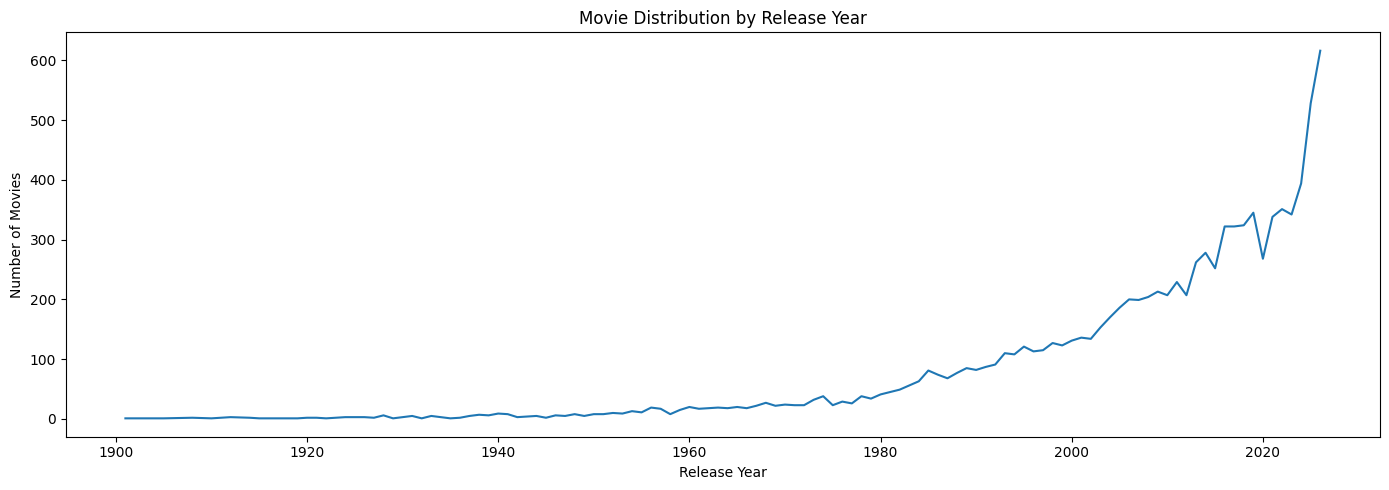

In [ ]:
print("Dataset shape:", tmdb_df.shape)

print("\nYear range:")
print("Earliest:", tmdb_df["release_year"].min())
print("Latest:", tmdb_df["release_year"].max())

print("\n2026 movies:", (tmdb_df["release_year"] == 2026).sum())

display(tmdb_df[["title", "release_year", "overview"]].head())

plt.figure(figsize=(14, 5))
tmdb_df["release_year"].value_counts().sort_index().plot()

plt.title("Movie Distribution by Release Year")
plt.xlabel("Release Year")
plt.ylabel("Number of Movies")
plt.tight_layout()
plt.show()

### Genre Selection

To keep the multi-class classification problem manageable, the six most common
genres are selected. Movies are assigned their first listed TMDB genre as the
primary genre, and the dataset is stratified when reduced to approximately
7,000 samples.

In [ ]:
# Convert genre IDs to genre names
tmdb_df["genres"] = tmdb_df["genre_ids"].apply(
    lambda ids: [genre_map[g] for g in ids if g in genre_map]
)

# Use the first listed genre as the primary genre
tmdb_df["genre"] = tmdb_df["genres"].apply(
    lambda x: x[0] if x else None
)

# Remove movies without a usable genre
tmdb_df = tmdb_df.dropna(subset=["genre"])

# Find the 6 most common genres
top_genres = tmdb_df["genre"].value_counts().head(6).index.tolist()

print("Selected genres:")
print(top_genres)

print("\nGenre distribution before sampling:")
print(tmdb_df["genre"].value_counts().head(10))

# Keep only the selected genres
tmdb_df = tmdb_df[
    tmdb_df["genre"].isin(top_genres)
].copy()

# Limit to approximately 7,000 movies while preserving class proportions
TARGET_SIZE = min(7000, len(tmdb_df))

if len(tmdb_df) > TARGET_SIZE:
    tmdb_df, _ = train_test_split(
        tmdb_df,
        train_size=TARGET_SIZE,
        stratify=tmdb_df["genre"],
        random_state=SEED
    )

tmdb_df = tmdb_df.reset_index(drop=True)

print("\n Final dataset:", tmdb_df.shape)

print("\nFinal genre distribution:")
print(tmdb_df["genre"].value_counts())

Selected genres:
['Drama', 'Action', 'Comedy', 'Horror', 'Animation', 'Adventure']

Genre distribution before sampling:
genre
Drama          2015
Action         1484
Comedy         1357
Horror          812
Animation       680
Adventure       516
Thriller        500
Crime           410
Romance         396
Documentary     320
Name: count, dtype: int64

 Final dataset: (6864, 8)

Final genre distribution:
genre
Drama        2015
Action       1484
Comedy       1357
Horror        812
Animation     680
Adventure     516
Name: count, dtype: int64


# 4. Exploratory Data Analysis

The genre distribution is examined to identify class imbalance before training.
The release-year distribution is also visualized to understand the temporal
coverage of the dataset.

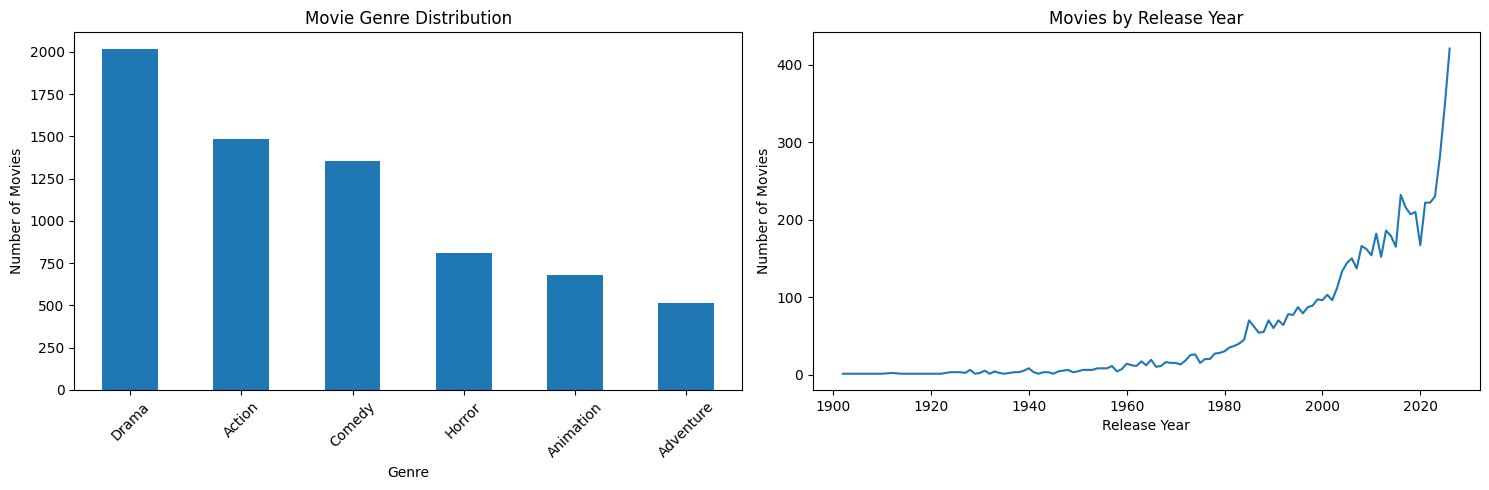

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(15, 5))

# Genre distribution
tmdb_df["genre"].value_counts().plot(
    kind="bar",
    ax=axes[0]
)

axes[0].set_title("Movie Genre Distribution")
axes[0].set_xlabel("Genre")
axes[0].set_ylabel("Number of Movies")
axes[0].tick_params(axis="x", rotation=45)

# Release year distribution
tmdb_df["release_year"].value_counts().sort_index().plot(
    ax=axes[1]
)

axes[1].set_title("Movies by Release Year")
axes[1].set_xlabel("Release Year")
axes[1].set_ylabel("Number of Movies")

plt.tight_layout()
plt.show()

# 5. Data Splitting and Label Encoding

The dataset is divided into training, validation and test sets using stratified
sampling so that the genre proportions remain similar across the three subsets.
The categorical genre labels are then converted into numerical class labels.

Stratification is used so that the relative proportions of the six genres are
preserved across the training, validation and test sets.

In [ ]:
from sklearn.model_selection import train_test_split

X = tmdb_df["overview"].values
y = tmdb_df["genre"].values

# 70% train, 30% temporary
X_train, X_temp, y_train, y_temp = train_test_split(
    X, y,
    test_size=0.30,
    stratify=y,
    random_state=SEED
)

# Split remaining 30% equally → 15% validation, 15% test
X_val, X_test, y_val, y_test = train_test_split(
    X_temp, y_temp,
    test_size=0.50,
    stratify=y_temp,
    random_state=SEED
)

print("Training:", len(X_train))
print("Validation:", len(X_val))
print("Test:", len(X_test))

print("\nTraining distribution:")
print(pd.Series(y_train).value_counts())

Training: 4804
Validation: 1030
Test: 1030

Training distribution:
Drama        1410
Action       1039
Comedy        950
Horror        568
Animation     476
Adventure     361
Name: count, dtype: int64


In [ ]:
label_encoder = LabelEncoder()

y_train_encoded = label_encoder.fit_transform(y_train)
y_val_encoded = label_encoder.transform(y_val)
y_test_encoded = label_encoder.transform(y_test)

class_names = label_encoder.classes_
num_classes = len(class_names)

print("Classes:", class_names)
print("Number of classes:", num_classes)

Classes: ['Action' 'Adventure' 'Animation' 'Comedy' 'Drama' 'Horror']
Number of classes: 6


# 6. Text Representation with MiniLM

Movie plot summaries are converted into numerical representations using the
pretrained `all-MiniLM-L6-v2` sentence-transformer.

The encoder is kept frozen; therefore, its parameters are not updated during
classifier training.

Each plot is represented by a 384-dimensional embedding, which becomes the
input to the trainable MLP classifier.

In [ ]:
device = "cuda" if torch.cuda.is_available() else "cpu"

print("Embedding device:", device)

embedding_model = SentenceTransformer(
    "sentence-transformers/all-MiniLM-L6-v2",
    device=device
)

def create_embeddings(texts):
    return embedding_model.encode(
        texts.tolist(),
        batch_size=32,
        show_progress_bar=True,
        convert_to_numpy=True
    )

X_train_emb = create_embeddings(X_train)
X_val_emb = create_embeddings(X_val)
X_test_emb = create_embeddings(X_test)

print("\nEmbedding shapes:")
print("Train:", X_train_emb.shape)
print("Validation:", X_val_emb.shape)
print("Test:", X_test_emb.shape)

Embedding device: cpu


modules.json:   0%|          | 0.00/349 [00:00<?, ?B/s]

config_sentence_transformers.json:   0%|          | 0.00/116 [00:00<?, ?B/s]

README.md:   0%|          | 0.00/10.5k [00:00<?, ?B/s]

sentence_bert_config.json:   0%|          | 0.00/53.0 [00:00<?, ?B/s]

...

config.json:   0%|          | 0.00/190 [00:00<?, ?B/s]

Batches:   0%|          | 0/151 [00:00<?, ?it/s]

Batches:   0%|          | 0/33 [00:00<?, ?it/s]

Batches:   0%|          | 0/33 [00:00<?, ?it/s]


Embedding shapes:
Train: (4804, 384)
Validation: (1030, 384)
Test: (1030, 384)


In [ ]:
# Convert embeddings and labels to PyTorch tensors

X_train_tensor = torch.tensor(X_train_emb, dtype=torch.float32)
X_val_tensor   = torch.tensor(X_val_emb, dtype=torch.float32)
X_test_tensor  = torch.tensor(X_test_emb, dtype=torch.float32)

y_train_tensor = torch.tensor(y_train_encoded, dtype=torch.long)
y_val_tensor   = torch.tensor(y_val_encoded, dtype=torch.long)
y_test_tensor  = torch.tensor(y_test_encoded, dtype=torch.long)

# Create DataLoaders
BATCH_SIZE = 64

train_loader = DataLoader(
    TensorDataset(X_train_tensor, y_train_tensor),
    batch_size=BATCH_SIZE,
    shuffle=True
)

val_loader = DataLoader(
    TensorDataset(X_val_tensor, y_val_tensor),
    batch_size=BATCH_SIZE,
    shuffle=False
)

test_loader = DataLoader(
    TensorDataset(X_test_tensor, y_test_tensor),
    batch_size=BATCH_SIZE,
    shuffle=False
)

print(" PyTorch datasets ready")
print("Input dimension:", X_train_tensor.shape[1])
print("Number of classes:", num_classes)
print("Batch size:", BATCH_SIZE)

 PyTorch datasets ready
Input dimension: 384
Number of classes: 6
Batch size: 64


# 7. Model Development and Complexity Analysis

In [ ]:
def train_model(
    model,
    train_loader,
    val_loader,
    epochs=10,
    lr=0.001,
    weight_decay=0,
    patience=None
):
    criterion = nn.CrossEntropyLoss()

    optimizer = torch.optim.Adam(
        model.parameters(),
        lr=lr,
        weight_decay=weight_decay
    )

    train_losses = []
    val_losses = []
    val_accuracies = []

    best_val_loss = float("inf")
    best_state = None
    best_epoch = 0
    patience_counter = 0

    for epoch in range(epochs):

        # ---------- Training ----------
        model.train()
        running_loss = 0

        for X_batch, y_batch in train_loader:
            X_batch = X_batch.to(device)
            y_batch = y_batch.to(device)

            optimizer.zero_grad()

            outputs = model(X_batch)
            loss = criterion(outputs, y_batch)

            loss.backward()
            optimizer.step()

            running_loss += loss.item() * X_batch.size(0)

        train_loss = running_loss / len(train_loader.dataset)

        # ---------- Validation ----------
        model.eval()
        val_loss_total = 0
        correct = 0

        with torch.no_grad():
            for X_batch, y_batch in val_loader:
                X_batch = X_batch.to(device)
                y_batch = y_batch.to(device)

                outputs = model(X_batch)
                loss = criterion(outputs, y_batch)

                val_loss_total += loss.item() * X_batch.size(0)

                predictions = outputs.argmax(dim=1)
                correct += (predictions == y_batch).sum().item()

        val_loss = val_loss_total / len(val_loader.dataset)
        val_accuracy = correct / len(val_loader.dataset)

        train_losses.append(train_loss)
        val_losses.append(val_loss)
        val_accuracies.append(val_accuracy)

        print(
            f"Epoch {epoch+1:02d}/{epochs} | "
            f"Train Loss: {train_loss:.4f} | "
            f"Val Loss: {val_loss:.4f} | "
            f"Val Acc: {val_accuracy:.4f}"
        )

        # ---------- Early stopping ----------
        if val_loss < best_val_loss:
            best_val_loss = val_loss
            best_state = model.state_dict()
            best_epoch = epoch + 1
            patience_counter = 0

        elif patience is not None:
            patience_counter += 1

            if patience_counter >= patience:
                print(f"\nEarly stopping at epoch {epoch+1}")
                break

    # Restore best model
    if best_state is not None:
        model.load_state_dict(best_state)

    history = {
        "train_loss": train_losses,
        "val_loss": val_losses,
        "val_accuracy": val_accuracies,
        "best_epoch": best_epoch
    }

    return model, history

## 7.1 Underfitting Baseline

A deliberately small neural network is trained first. Its limited capacity
provides a baseline for identifying high-bias / underfitting behavior.

In [ ]:
class UnderfitModel(nn.Module):
    def __init__(self, input_size=384, num_classes=6):
        super().__init__()

        self.network = nn.Sequential(
            nn.Linear(input_size, 32),
            nn.ReLU(),
            nn.Linear(32, num_classes)
        )

    def forward(self, x):
        return self.network(x)


underfit_model = UnderfitModel(
    input_size=384,
    num_classes=num_classes
).to(device)

print(underfit_model)

UnderfitModel(
  (network): Sequential(
    (0): Linear(in_features=384, out_features=32, bias=True)
    (1): ReLU()
    (2): Linear(in_features=32, out_features=6, bias=True)
  )
)


In [ ]:
underfit_model, underfit_history = train_model(
    underfit_model,
    train_loader,
    val_loader,
    epochs=8,
    lr=0.001
)

Epoch 01/8 | Train Loss: 1.7304 | Val Loss: 1.6049 | Val Acc: 0.3447
Epoch 02/8 | Train Loss: 1.4884 | Val Loss: 1.4139 | Val Acc: 0.4583
Epoch 03/8 | Train Loss: 1.3128 | Val Loss: 1.2883 | Val Acc: 0.5155
Epoch 04/8 | Train Loss: 1.2020 | Val Loss: 1.2136 | Val Acc: 0.5534
Epoch 05/8 | Train Loss: 1.1370 | Val Loss: 1.1734 | Val Acc: 0.5592
Epoch 06/8 | Train Loss: 1.0968 | Val Loss: 1.1499 | Val Acc: 0.5621
Epoch 07/8 | Train Loss: 1.0692 | Val Loss: 1.1380 | Val Acc: 0.5650
Epoch 08/8 | Train Loss: 1.0505 | Val Loss: 1.1332 | Val Acc: 0.5612


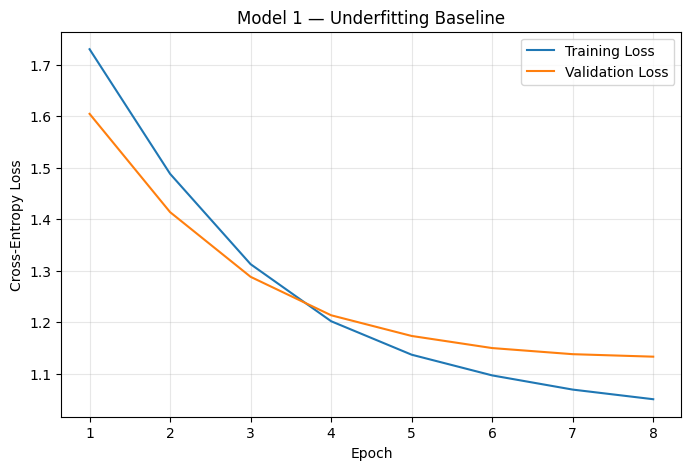

In [ ]:
plt.figure(figsize=(8, 5))

plt.plot(
    range(1, len(underfit_history["train_loss"]) + 1),
    underfit_history["train_loss"],
    label="Training Loss"
)

plt.plot(
    range(1, len(underfit_history["val_loss"]) + 1),
    underfit_history["val_loss"],
    label="Validation Loss"
)

plt.xlabel("Epoch")
plt.ylabel("Cross-Entropy Loss")
plt.title("Model 1 — Underfitting Baseline")
plt.legend()
plt.grid(alpha=0.3)

plt.show()

## 7.2 Overfitting Experiment

A much larger MLP is deliberately trained without dropout or weight decay.
This provides a high-variance example and demonstrates how excessive model
capacity can cause overfitting.

In [ ]:
class OverfitModel(nn.Module):
    def __init__(self, input_size=384, num_classes=6):
        super().__init__()

        self.network = nn.Sequential(
            nn.Linear(input_size, 512),
            nn.ReLU(),
            nn.Linear(512, 256),
            nn.ReLU(),
            nn.Linear(256, 128),
            nn.ReLU(),
            nn.Linear(128, num_classes)
        )

    def forward(self, x):
        return self.network(x)


overfit_model = OverfitModel(
    input_size=384,
    num_classes=num_classes
).to(device)

print(overfit_model)

OverfitModel(
  (network): Sequential(
    (0): Linear(in_features=384, out_features=512, bias=True)
    (1): ReLU()
    (2): Linear(in_features=512, out_features=256, bias=True)
    (3): ReLU()
    (4): Linear(in_features=256, out_features=128, bias=True)
    (5): ReLU()
    (6): Linear(in_features=128, out_features=6, bias=True)
  )
)


In [ ]:
overfit_model, overfit_history = train_model(
    overfit_model,
    train_loader,
    val_loader,
    epochs=30,
    lr=0.001
)

Epoch 01/30 | Train Loss: 1.4983 | Val Loss: 1.2890 | Val Acc: 0.5320
Epoch 02/30 | Train Loss: 1.1600 | Val Loss: 1.1459 | Val Acc: 0.5583
Epoch 03/30 | Train Loss: 1.0544 | Val Loss: 1.1563 | Val Acc: 0.5544
Epoch 04/30 | Train Loss: 0.9922 | Val Loss: 1.1413 | Val Acc: 0.5699
Epoch 05/30 | Train Loss: 0.9303 | Val Loss: 1.1438 | Val Acc: 0.5718
Epoch 06/30 | Train Loss: 0.8528 | Val Loss: 1.2182 | Val Acc: 0.5534
Epoch 07/30 | Train Loss: 0.7799 | Val Loss: 1.2131 | Val Acc: 0.5621
Epoch 08/30 | Train Loss: 0.6769 | Val Loss: 1.2460 | Val Acc: 0.5534
Epoch 09/30 | Train Loss: 0.5414 | Val Loss: 1.4057 | Val Acc: 0.5320
Epoch 10/30 | Train Loss: 0.4062 | Val Loss: 1.4785 | Val Acc: 0.5427
Epoch 11/30 | Train Loss: 0.2684 | Val Loss: 1.6610 | Val Acc: 0.5330
Epoch 12/30 | Train Loss: 0.1645 | Val Loss: 1.9347 | Val Acc: 0.5350
Epoch 13/30 | Train Loss: 0.1056 | Val Loss: 2.1491 | Val Acc: 0.5204
Epoch 14/30 | Train Loss: 0.0533 | Val Loss: 2.3685 | Val Acc: 0.5184
Epoch 15/30 | Train 

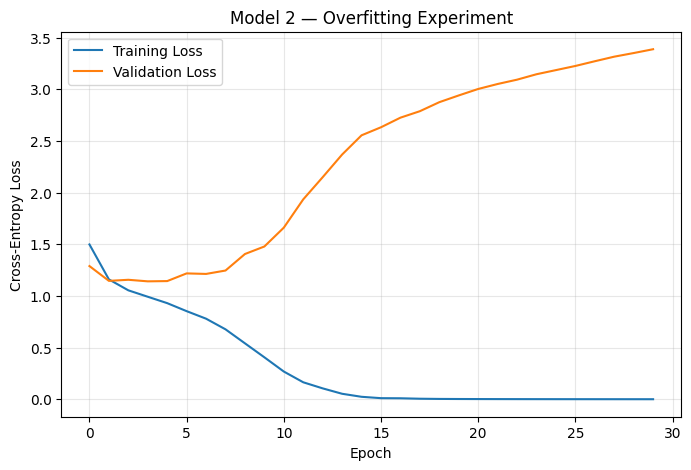

In [ ]:
plt.figure(figsize=(8, 5))

plt.plot(
    overfit_history["train_loss"],
    label="Training Loss"
)

plt.plot(
    overfit_history["val_loss"],
    label="Validation Loss"
)

plt.xlabel("Epoch")
plt.ylabel("Cross-Entropy Loss")
plt.title("Model 2 — Overfitting Experiment")
plt.legend()
plt.grid(alpha=0.3)

plt.show()

## 7.3 Final Model

The final classifier uses a moderate architecture:

**384 → 128 → 64 → 6**

Dropout and weight decay are introduced as regularization techniques.
Early stopping monitors validation loss to prevent unnecessary training.

In [ ]:
class FinalModel(nn.Module):
    def __init__(self, input_size=384, num_classes=6):
        super().__init__()

        self.network = nn.Sequential(
            nn.Linear(input_size, 128),
            nn.ReLU(),
            nn.Dropout(0.3),

            nn.Linear(128, 64),
            nn.ReLU(),
            nn.Dropout(0.3),

            nn.Linear(64, num_classes)
        )

    def forward(self, x):
        return self.network(x)


final_model = FinalModel(
    input_size=384,
    num_classes=num_classes
).to(device)

print(final_model)

FinalModel(
  (network): Sequential(
    (0): Linear(in_features=384, out_features=128, bias=True)
    (1): ReLU()
    (2): Dropout(p=0.3, inplace=False)
    (3): Linear(in_features=128, out_features=64, bias=True)
    (4): ReLU()
    (5): Dropout(p=0.3, inplace=False)
    (6): Linear(in_features=64, out_features=6, bias=True)
  )
)


In [ ]:
final_model, final_history = train_model(
    final_model,
    train_loader,
    val_loader,
    epochs=30,
    lr=0.001,
    weight_decay=0.0001,
    patience=3
)

print(
    "\nBest validation epoch:",
    final_history["best_epoch"]
)

Epoch 01/30 | Train Loss: 1.6381 | Val Loss: 1.4745 | Val Acc: 0.4049
Epoch 02/30 | Train Loss: 1.3498 | Val Loss: 1.2745 | Val Acc: 0.5252
Epoch 03/30 | Train Loss: 1.2142 | Val Loss: 1.1778 | Val Acc: 0.5466
Epoch 04/30 | Train Loss: 1.1360 | Val Loss: 1.1624 | Val Acc: 0.5505
Epoch 05/30 | Train Loss: 1.1060 | Val Loss: 1.1419 | Val Acc: 0.5650
Epoch 06/30 | Train Loss: 1.0894 | Val Loss: 1.1380 | Val Acc: 0.5709
Epoch 07/30 | Train Loss: 1.0597 | Val Loss: 1.1302 | Val Acc: 0.5709
Epoch 08/30 | Train Loss: 1.0416 | Val Loss: 1.1362 | Val Acc: 0.5806
Epoch 09/30 | Train Loss: 1.0235 | Val Loss: 1.1295 | Val Acc: 0.5709
Epoch 10/30 | Train Loss: 1.0022 | Val Loss: 1.1346 | Val Acc: 0.5845
Epoch 11/30 | Train Loss: 0.9887 | Val Loss: 1.1436 | Val Acc: 0.5699
Epoch 12/30 | Train Loss: 0.9779 | Val Loss: 1.1370 | Val Acc: 0.5748

Early stopping at epoch 12

Best validation epoch: 9


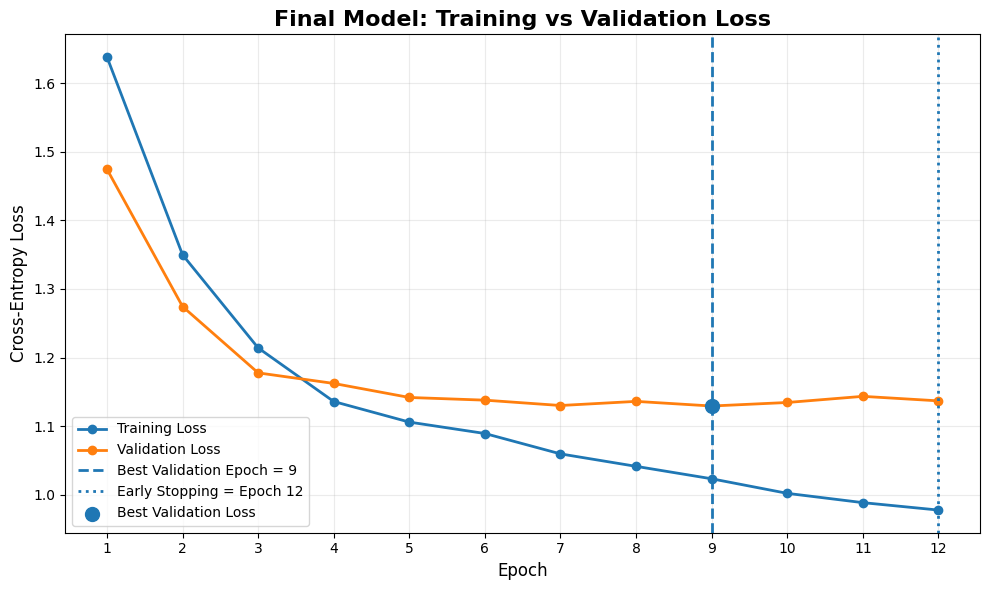

Best validation epoch: 9
Early stopping epoch: 12


In [ ]:
train_loss = final_history["train_loss"]
val_loss = final_history["val_loss"]

best_epoch = final_history["best_epoch"]
early_stop_epoch = len(val_loss)

epochs = range(1, len(train_loss) + 1)

plt.figure(figsize=(10, 6))

plt.plot(epochs, train_loss, marker="o", linewidth=2, label="Training Loss")
plt.plot(epochs, val_loss, marker="o", linewidth=2, label="Validation Loss")

plt.axvline(
    best_epoch,
    linestyle="--",
    linewidth=2,
    label=f"Best Validation Epoch = {best_epoch}"
)

plt.axvline(
    early_stop_epoch,
    linestyle=":",
    linewidth=2,
    label=f"Early Stopping = Epoch {early_stop_epoch}"
)

plt.scatter(
    best_epoch,
    val_loss[best_epoch - 1],
    s=100,
    zorder=5,
    label="Best Validation Loss"
)

plt.title(
    "Final Model: Training vs Validation Loss",
    fontsize=16,
    fontweight="bold"
)

plt.xlabel("Epoch", fontsize=12)
plt.ylabel("Cross-Entropy Loss", fontsize=12)

plt.xticks(epochs)
plt.grid(alpha=0.25)
plt.legend()
plt.tight_layout()
plt.show()

print(f"Best validation epoch: {best_epoch}")
print(f"Early stopping epoch: {early_stop_epoch}")

# 8. Bias–Variance and Model Complexity

Bias and variance are analyzed qualitatively through controlled experiments.

The deliberately small model represents an underfitting/high-bias case, while
the larger unregularized model represents an overfitting/high-variance case.
The final model introduces moderate complexity and regularization to obtain a
better balance.

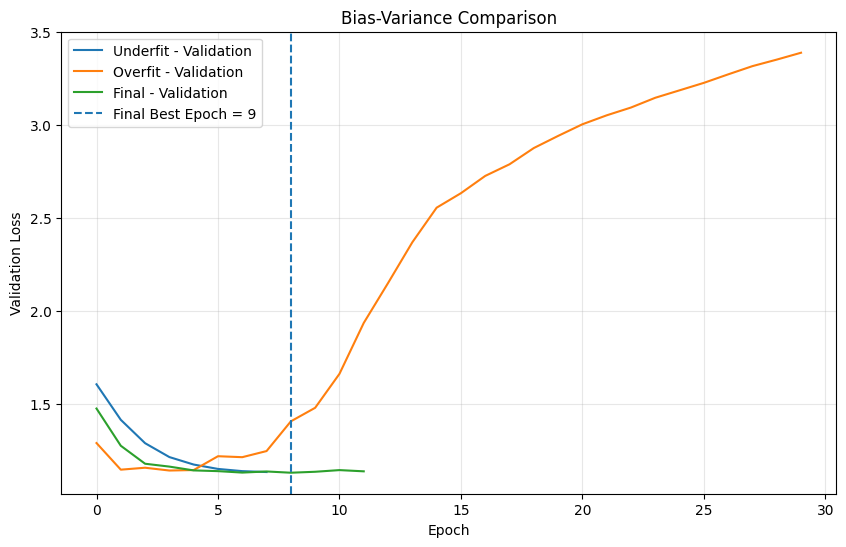

In [ ]:
plt.figure(figsize=(10, 6))

# Underfit
plt.plot(
    underfit_history["val_loss"],
    label="Underfit - Validation"
)

# Overfit
plt.plot(
    overfit_history["val_loss"],
    label="Overfit - Validation"
)

# Final model
plt.plot(
    final_history["val_loss"],
    label="Final - Validation"
)

plt.axvline(
    final_history["best_epoch"] - 1,
    linestyle="--",
    label=f"Final Best Epoch = {final_history['best_epoch']}"
)

plt.xlabel("Epoch")
plt.ylabel("Validation Loss")
plt.title("Bias-Variance Comparison")
plt.legend()
plt.grid(alpha=0.3)

plt.show()

# 9. Stratified 5-Fold Cross-Validation

Five-fold stratified cross-validation is performed on the training data to
evaluate whether the final model's performance is stable across different
training/validation splits.

Accuracy and macro F1 are reported as mean ± standard deviation.

In [ ]:
from sklearn.model_selection import StratifiedKFold
from sklearn.metrics import accuracy_score, f1_score

skf = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=SEED
)

cv_accuracy = []
cv_f1 = []

for fold, (train_idx, val_idx) in enumerate(
    skf.split(X_train_emb, y_train_encoded), 1
):

    # Create fresh model
    model = FinalModel(
        input_size=384,
        num_classes=num_classes
    ).to(device)

    # Create fold datasets
    fold_train = TensorDataset(
        torch.tensor(X_train_emb[train_idx], dtype=torch.float32),
        torch.tensor(y_train_encoded[train_idx], dtype=torch.long)
    )

    fold_val = TensorDataset(
        torch.tensor(X_train_emb[val_idx], dtype=torch.float32),
        torch.tensor(y_train_encoded[val_idx], dtype=torch.long)
    )

    fold_train_loader = DataLoader(
        fold_train,
        batch_size=64,
        shuffle=True
    )

    fold_val_loader = DataLoader(
        fold_val,
        batch_size=64,
        shuffle=False
    )

    # Train
    model, history = train_model(
        model,
        fold_train_loader,
        fold_val_loader,
        epochs=30,
        lr=0.001,
        weight_decay=0.0001,
        patience=3
    )

    # Predict validation fold
    model.eval()
    predictions = []

    with torch.no_grad():
        for X_batch, _ in fold_val_loader:
            X_batch = X_batch.to(device)
            outputs = model(X_batch)
            predictions.extend(
                outputs.argmax(dim=1).cpu().numpy()
            )

    true_labels = y_train_encoded[val_idx]

    acc = accuracy_score(true_labels, predictions)
    f1 = f1_score(
        true_labels,
        predictions,
        average="macro"
    )

    cv_accuracy.append(acc)
    cv_f1.append(f1)

    print(
        f"Fold {fold}: "
        f"Accuracy = {acc:.4f}, "
        f"Macro F1 = {f1:.4f}"
    )

print("\n===== 5-FOLD CROSS-VALIDATION =====")
print(f"Accuracy: {np.mean(cv_accuracy):.4f} ± {np.std(cv_accuracy):.4f}")
print(f"Macro F1: {np.mean(cv_f1):.4f} ± {np.std(cv_f1):.4f}")

Epoch 01/30 | Train Loss: 1.6790 | Val Loss: 1.5242 | Val Acc: 0.3975
Epoch 02/30 | Train Loss: 1.3847 | Val Loss: 1.2799 | Val Acc: 0.4807
Epoch 03/30 | Train Loss: 1.2258 | Val Loss: 1.1953 | Val Acc: 0.5151
Epoch 04/30 | Train Loss: 1.1620 | Val Loss: 1.1712 | Val Acc: 0.5307
Epoch 05/30 | Train Loss: 1.1196 | Val Loss: 1.1560 | Val Acc: 0.5390
Epoch 06/30 | Train Loss: 1.0907 | Val Loss: 1.1481 | Val Acc: 0.5525
Epoch 07/30 | Train Loss: 1.0775 | Val Loss: 1.1410 | Val Acc: 0.5380
Epoch 08/30 | Train Loss: 1.0520 | Val Loss: 1.1381 | Val Acc: 0.5463
Epoch 09/30 | Train Loss: 1.0452 | Val Loss: 1.1419 | Val Acc: 0.5473
Epoch 10/30 | Train Loss: 1.0190 | Val Loss: 1.1382 | Val Acc: 0.5338
Epoch 11/30 | Train Loss: 0.9940 | Val Loss: 1.1397 | Val Acc: 0.5463

Early stopping at epoch 11
Fold 1: Accuracy = 0.5463, Macro F1 = 0.4732
Epoch 01/30 | Train Loss: 1.6926 | Val Loss: 1.5470 | Val Acc: 0.4100
Epoch 02/30 | Train Loss: 1.4135 | Val Loss: 1.3441 | Val Acc: 0.4506
Epoch 03/30 | Tra

# 10. Final Test Evaluation

The final model is evaluated once on the held-out test set.

Because the genre distribution is imbalanced, accuracy is reported alongside
macro precision, macro recall, macro F1, weighted F1, and per-class metrics.

In [ ]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report
)

final_model.eval()

test_predictions = []

with torch.no_grad():

    for X_batch, _ in test_loader:

        X_batch = X_batch.to(device)

        outputs = final_model(X_batch)

        predictions = outputs.argmax(dim=1)

        test_predictions.extend(
            predictions.cpu().numpy()
        )


# ===== OVERALL METRICS =====

test_accuracy = accuracy_score(
    y_test_encoded,
    test_predictions
)

test_precision = precision_score(
    y_test_encoded,
    test_predictions,
    average="macro",
    zero_division=0
)

test_recall = recall_score(
    y_test_encoded,
    test_predictions,
    average="macro",
    zero_division=0
)

test_macro_f1 = f1_score(
    y_test_encoded,
    test_predictions,
    average="macro"
)

test_weighted_f1 = f1_score(
    y_test_encoded,
    test_predictions,
    average="weighted"
)


print("===== FINAL TEST RESULTS =====")

print(f"Accuracy:          {test_accuracy:.4f}")
print(f"Macro Precision:   {test_precision:.4f}")
print(f"Macro Recall:      {test_recall:.4f}")
print(f"Macro F1:          {test_macro_f1:.4f}")
print(f"Weighted F1:       {test_weighted_f1:.4f}")


# ===== PER-CLASS METRICS =====

print("\n===== PER-CLASS RESULTS =====")

print(
    classification_report(
        y_test_encoded,
        test_predictions,
        target_names=class_names,
        zero_division=0
    )
)

===== FINAL TEST RESULTS =====
Accuracy:          0.5796
Macro Precision:   0.5465
Macro Recall:      0.5225
Macro F1:          0.5145
Weighted F1:       0.5653

===== PER-CLASS RESULTS =====
              precision    recall  f1-score   support

      Action       0.60      0.74      0.66       223
   Adventure       0.44      0.10      0.17        77
   Animation       0.55      0.58      0.56       102
      Comedy       0.56      0.49      0.52       204
       Drama       0.63      0.65      0.64       302
      Horror       0.49      0.58      0.53       122

    accuracy                           0.58      1030
   macro avg       0.55      0.52      0.51      1030
weighted avg       0.57      0.58      0.57      1030



# 11. Confusion Matrix

The confusion matrix shows how predictions are distributed across the six
genres and highlights which genres are most frequently confused with one another.

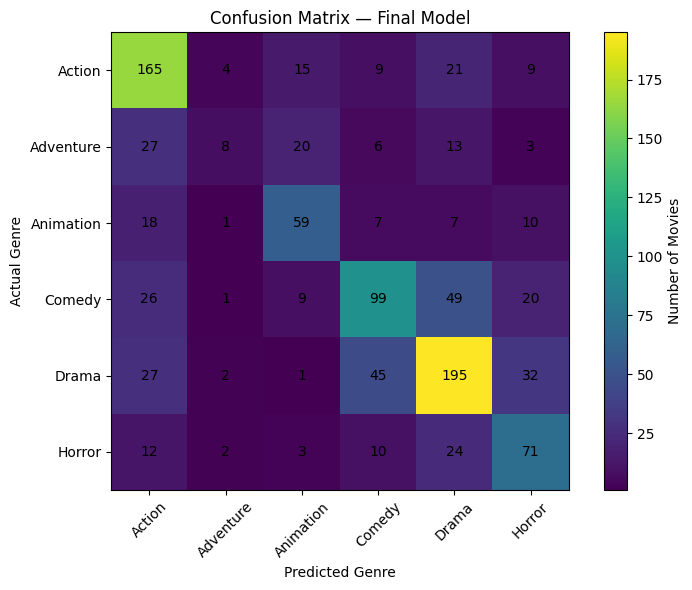

In [ ]:
cm = confusion_matrix(
    y_test_encoded,
    test_predictions
)

plt.figure(figsize=(8, 6))

plt.imshow(cm)

plt.title("Confusion Matrix — Final Model")
plt.xlabel("Predicted Genre")
plt.ylabel("Actual Genre")

plt.xticks(
    range(num_classes),
    class_names,
    rotation=45
)

plt.yticks(
    range(num_classes),
    class_names
)

for i in range(num_classes):
    for j in range(num_classes):
        plt.text(
            j,
            i,
            cm[i, j],
            ha="center",
            va="center"
        )

plt.colorbar(label="Number of Movies")
plt.tight_layout()
plt.show()

# 12. Model Persistence

The trained classifier is saved to Google Drive so that it can be reused
without retraining.

In [ ]:

import os
import torch

save_dir = "/content/drive/MyDrive/Movie_Genre_Classifier"
os.makedirs(save_dir, exist_ok=True)

model_path = os.path.join(save_dir, "final_movie_genre_model.pth")

torch.save({
    "model_state_dict": final_model.state_dict(),
    "input_size": 384,
    "num_classes": num_classes,
    "class_names": class_names
}, model_path)

print("Model saved successfully!")
print("Location:", model_path)

Model saved successfully!
Location: /content/drive/MyDrive/Movie_Genre_Classifier/final_movie_genre_model.pth


In [ ]:
checkpoint = torch.load(
    "/content/drive/MyDrive/Movie_Genre_Classifier/final_movie_genre_model.pth",
    map_location=device,
    weights_only=False
)

loaded_model = FinalModel(
    input_size=checkpoint["input_size"],
    num_classes=checkpoint["num_classes"]
).to(device)

loaded_model.load_state_dict(
    checkpoint["model_state_dict"]
)

loaded_model.eval()

class_names = checkpoint["class_names"]

print("Model loaded successfully!")
print("Classes:", class_names)

Model loaded successfully!
Classes: ['Action' 'Adventure' 'Animation' 'Comedy' 'Drama' 'Horror']


# 13. Single Movie Prediction

In [ ]:

from sentence_transformers import SentenceTransformer

# Load the same frozen MiniLM model used for embeddings
embedding_model = SentenceTransformer(
    "sentence-transformers/all-MiniLM-L6-v2"
)

plot = """
A young woman discovers a mysterious house in the middle of a forest.
As she explores it, strange events begin happening and she realizes
that something supernatural is following her.
"""

# Generate MiniLM embedding
embedding = embedding_model.encode(
    plot,
    convert_to_numpy=True
)

# Convert embedding to tensor
X_new = torch.tensor(
    embedding,
    dtype=torch.float32
).unsqueeze(0).to(device)

# Predict
loaded_model.eval()

with torch.no_grad():
    output = loaded_model(X_new)
    predicted_class = output.argmax(dim=1).item()

print("Movie Plot:")
print(plot)

print("\nPredicted Genre:", class_names[predicted_class])

Loading weights:   0%|          | 0/103 [00:00<?, ?it/s]

Movie Plot:

A young woman discovers a mysterious house in the middle of a forest.
As she explores it, strange events begin happening and she realizes
that something supernatural is following her.


Predicted Genre: Horror


# 14. Interactive Movie Genre Demo

Enter a movie plot summary below and the trained model will predict its genre.

In [ ]:

import gradio as gr
import torch
import base64

# ---------------------------------------------------------
# BACKGROUND
# ---------------------------------------------------------

with open("background.jpeg", "rb") as f:
    image_base64 = base64.b64encode(f.read()).decode("utf-8")

background_url = f"data:image/jpeg;base64,{image_base64}"


# ---------------------------------------------------------
# PREDICTION FUNCTION
# ---------------------------------------------------------

def predict_genre(plot):
    if not plot or not plot.strip():
        return "Please enter a movie plot."

    embedding = model.encode(
        [plot],
        convert_to_tensor=True
    )

    final_model.eval()

    with torch.no_grad():
        output = final_model(embedding)
        prediction = torch.argmax(output, dim=1).item()

    genre = label_encoder.inverse_transform([prediction])[0]

    return genre

custom_css = f"""

/* =====================================================
   ENTIRE PAGE
   ===================================================== */

html,
body,
.gradio-container {{
    margin: 0 !important;
    padding: 0 !important;
    min-height: 100vh !important;

    background-image:
        linear-gradient(
            rgba(255, 245, 248, 0.18),
            rgba(255, 245, 248, 0.18)
        ),
        url("{background_url}") !important;

    background-size: cover !important;
    background-position: center !important;
    background-attachment: fixed !important;

    font-family: Georgia, "Times New Roman", serif !important;
}}


/* Remove Gradio's default background layers */

.gradio-container {{
    background-color: transparent !important;
}}

.contain {{
    background: transparent !important;
}}


/* =====================================================
   MAIN WHITE CARD
   ===================================================== */

#main-card {{
    width: min(760px, 90%) !important;
    margin: 60px auto !important;
    padding: 48px 55px 52px 55px !important;

    background: rgba(255, 253, 253, 0.94) !important;

    border: 1px solid rgba(255, 255, 255, 0.9) !important;
    border-radius: 30px !important;

    box-shadow:
        0 20px 60px rgba(150, 80, 105, 0.18) !important;

    backdrop-filter: blur(8px) !important;
    -webkit-backdrop-filter: blur(8px) !important;
}}


/* =====================================================
   SMALL TOP TEXT
   ===================================================== */

#eyebrow,
#eyebrow p {{
    color: #c96f8d !important;
    -webkit-text-fill-color: #c96f8d !important;

    text-align: center !important;

    font-family: Georgia, "Times New Roman", serif !important;
    font-size: 12px !important;
    font-weight: bold !important;

    letter-spacing: 4px !important;

    margin: 0 0 12px 0 !important;
}}


/* =====================================================
   MAIN TITLE
   ===================================================== */

#title,
#title h1,
#title h1 span {{
    color: #b84f73 !important;
    -webkit-text-fill-color: #b84f73 !important;

    text-align: center !important;

    font-family: Georgia, "Times New Roman", serif !important;

    font-size: 46px !important;
    font-weight: 600 !important;

    line-height: 1.15 !important;

    margin: 0 !important;
    padding: 0 !important;
}}


/* =====================================================
   SUBTITLE
   ===================================================== */

#subtitle,
#subtitle h3,
#subtitle p,
#subtitle span {{
    color: #8f6575 !important;
    -webkit-text-fill-color: #8f6575 !important;

    text-align: center !important;

    font-family: Georgia, "Times New Roman", serif !important;

    font-size: 16px !important;
    font-weight: normal !important;
    font-style: italic !important;

    line-height: 1.5 !important;

    margin-top: 10px !important;
    margin-bottom: 38px !important;

    opacity: 1 !important;
}}


/* =====================================================
   INPUT LABEL
   ===================================================== */

#plot-label,
#plot-label p {{
    color: #c96f8d !important;
    -webkit-text-fill-color: #c96f8d !important;

    font-family: Georgia, "Times New Roman", serif !important;

    font-size: 12px !important;
    font-weight: bold !important;

    letter-spacing: 2px !important;

    margin-bottom: 8px !important;
}}


/* =====================================================
   INPUT BOX — REMOVE BLACK EDGES
   ===================================================== */

#plot-input {{
    border: none !important;
    background: transparent !important;

    box-shadow: none !important;
}}


/* Outer textbox container */

#plot-input .wrap,
#plot-input .input-container,
#plot-input .block {{
    background: #fffafb !important;

    border: 1.5px solid #efc4d1 !important;

    border-radius: 18px !important;

    box-shadow: none !important;

    overflow: hidden !important;
}}


/* Actual textarea */

#plot-input textarea {{
    background: #fffafb !important;

    color: #694b57 !important;
    -webkit-text-fill-color: #694b57 !important;

    border: none !important;
    outline: none !important;

    box-shadow: none !important;

    font-family: Georgia, "Times New Roman", serif !important;
    font-size: 16px !important;

    line-height: 1.6 !important;

    padding: 18px !important;
}}


/* Placeholder */

#plot-input textarea::placeholder {{
    color: #bd9eaa !important;
    -webkit-text-fill-color: #bd9eaa !important;

    opacity: 1 !important;
}}


/* Focus */

#plot-input textarea:focus {{
    border: none !important;
    outline: none !important;

    box-shadow: none !important;
}}


/* =====================================================
   BUTTON
   ===================================================== */

#predict-btn {{
    margin-top: 22px !important;

    background: #d889a1 !important;

    border: none !important;
    border-radius: 16px !important;

    box-shadow: none !important;

    color: white !important;
    -webkit-text-fill-color: white !important;

    font-family: Georgia, "Times New Roman", serif !important;

    font-size: 16px !important;
    font-weight: bold !important;

    padding: 14px 25px !important;
}}


#predict-btn span,
#predict-btn p {{
    color: white !important;
    -webkit-text-fill-color: white !important;
}}


#predict-btn:hover {{
    background: #c97892 !important;

    box-shadow:
        0 8px 20px rgba(201, 111, 141, 0.25) !important;
}}


/* =====================================================
   OUTPUT CARD
   ===================================================== */

#output-card {{
    margin-top: 32px !important;
    padding: 25px !important;

    background: #fffafb !important;

    border: 1.5px solid #efc4d1 !important;
    border-radius: 20px !important;

    box-shadow: none !important;
}}


/* Output heading */

#output-label,
#output-label p {{
    color: #c96f8d !important;
    -webkit-text-fill-color: #c96f8d !important;

    text-align: center !important;

    font-family: Georgia, "Times New Roman", serif !important;

    font-size: 11px !important;
    font-weight: bold !important;

    letter-spacing: 2px !important;

    margin-bottom: 10px !important;
}}


/* =====================================================
   OUTPUT BOX — REMOVE BLACK EDGES
   ===================================================== */

#result {{
    border: none !important;
    background: transparent !important;

    box-shadow: none !important;
}}


#result .wrap,
#result .input-container,
#result .block {{
    background: transparent !important;

    border: none !important;

    box-shadow: none !important;
}}


#result textarea,
#result input {{
    background: transparent !important;

    border: none !important;
    outline: none !important;

    box-shadow: none !important;

    text-align: center !important;

    color: #b84f73 !important;
    -webkit-text-fill-color: #b84f73 !important;

    font-family: Georgia, "Times New Roman", serif !important;

    font-size: 28px !important;
    font-weight: bold !important;
}}


/* =====================================================
   REMOVE RANDOM GRADIO TEXT / BORDERS
   ===================================================== */

#main-card *,
#main-card label,
#main-card span,
#main-card p,
#main-card textarea,
#main-card input {{
    font-family: Georgia, "Times New Roman", serif !important;
}}


/* Kill default focus outlines */

#main-card *:focus {{
    outline: none !important;
}}


/* Hide footer */

footer {{
    display: none !important;
}}


/* =====================================================
   MOBILE
   ===================================================== */

@media (max-width: 700px) {{

    #main-card {{
        width: 88% !important;
        margin: 25px auto !important;

        padding: 35px 25px 40px 25px !important;
    }}

    #title h1 {{
        font-size: 36px !important;
    }}

    #subtitle p {{
        font-size: 14px !important;
    }}

}}

"""


# ---------------------------------------------------------
# GRADIO APP
# ---------------------------------------------------------

with gr.Blocks(
    css=custom_css,
    theme=gr.themes.Base(
        primary_hue="pink",
        neutral_hue="pink"
    ),
    title="Plot2Genre"
) as demo:

    with gr.Column(elem_id="main-card"):

        gr.Markdown(
            "P L O T 2 G E N R E",
            elem_id="eyebrow"
        )

        gr.Markdown(
            "# From Plot to Genre",
            elem_id="title"
        )

        gr.Markdown(
            "a little story · a little algorithm · a whole lot of cinema ♡",
            elem_id="subtitle"
        )

        gr.Markdown(
            "MOVIE PLOT",
            elem_id="plot-label"
        )

        plot_input = gr.Textbox(
            show_label=False,
            placeholder="Write or paste a movie plot here...",
            lines=7,
            elem_id="plot-input"
        )

        predict_button = gr.Button(
            "✦  Predict Genre",
            elem_id="predict-btn"
        )

        with gr.Column(elem_id="output-card"):

            gr.Markdown(
                "PREDICTED GENRE",
                elem_id="output-label"
            )

            result = gr.Textbox(
                show_label=False,
                placeholder="Your prediction will appear here",
                interactive=False,
                elem_id="result"
            )

        predict_button.click(
            fn=predict_genre,
            inputs=plot_input,
            outputs=result
        )


demo.launch()

/tmp/ipykernel_560/2671747327.py:450: UserWarning: The parameters have been moved from the Blocks constructor to the launch() method in Gradio 6.0: theme, css. Please pass these parameters to launch() instead.
  with gr.Blocks(


It looks like you are running Gradio on a hosted Jupyter notebook, which requires `share=True`. Automatically setting `share=True` (you can turn this off by setting `share=False` in `launch()` explicitly).

Colab notebook detected. To show errors in colab notebook, set debug=True in launch()
* Running on public URL: https://d12bcc1df021e8b2bf.gradio.live

This share link is temporary and will last for up to 1 week (best effort). For free permanent hosting and GPU upgrades, run `gradio deploy` from the terminal in the working directory to deploy to Hugging Face Spaces (https://huggingface.co/spaces)


# 15. Final Conclusion
## Conclusion

This project developed a deep learning based movie genre classifier using movie plot summaries.

The text was converted into 384-dimensional semantic embeddings using the pretrained
Sentence-BERT MiniLM model. A feed-forward neural network was then trained to classify
movies into six genres: Action, Adventure, Animation, Comedy, Drama, and Horror.

### Final Test Performance

- Accuracy: **57.96%**
- Macro Precision: **54.65%**
- Macro Recall: **52.25%**
- Macro F1: **51.45%**
- Weighted F1: **56.53%**

### Model Validation

Five-fold stratified cross-validation produced:

- Accuracy: **55.77% ± 1.94%**
- Macro F1: **48.29% ± 1.56%**

The underfitting and overfitting experiments demonstrated the bias–variance trade-off.
The final model used moderate complexity, dropout, weight decay, and early stopping
to achieve a better balance between learning the training data and generalizing to
unseen data.

The final model achieved its best validation performance at **Epoch 9**, and early
stopping occurred at **Epoch 12**.

Overall, the project demonstrates the deep learning workflow involving
text representation, model complexity analysis, cross-validation, early stopping,
and comprehensive evaluation using multiple classification metrics.